# **TO START**:
Select **File** from the menu at the top, then select **Save a copy in Drive**. This will create a new version of the notebook that you will own and will be able to make edits to. Rename the new file to include *your initials* at the end.

!['https://media-cldnry.s-nbcnews.com/image/upload/t_fit-1000w,f_auto,q_auto:best/msnbc/Components/Photos/060324/060324_glacier_hlg_1p.jpg'](https://media-cldnry.s-nbcnews.com/image/upload/t_fit-1000w,f_auto,q_auto:best/msnbc/Components/Photos/060324/060324_glacier_hlg_1p.jpg)

## **Temperature at Many Glacier, MT**
For this activity we'll walk through how to access, open, and display temperature data from NOAA/NCEI using their automated programming interface (API).

Read more about the weather station at Many Glacier, MT: https://www.ncei.noaa.gov/cdo-web/datasets/GHCND/stations/GHCND:USS0013A27S/detail

Throughout the activity, you will be asked to replace text that is inside [square brackets]. When prompted, replace the text and remove the square brackets before running your code cell.

In [ ]:
# STEP 0: Import python libraries

import pandas as pd  # working with datafames
import matplotlib.pyplot as plt # plotting
import numpy as np # working with arrays

In [ ]:
# STEP 1: Build endpoint request from NOAA/NCEI for Many Glacier, MT

many_glacier_url = (
    "https://www.ncei.noaa.gov/access/services/data/v1"
    "?dataset=daily-summaries"
    "&stations=USS0013A27S"
    "&startDate=1976-09-30"
    "&endDate=2025-02-21"
    "&dataTypes=TOBS,PRCP"
    "&includeStationName=true"
    "&includeStationLocation=1"
    "&units=standard")

many_glacier_url

'https://www.ncei.noaa.gov/access/services/data/v1?dataset=daily-summaries&stations=USS0013A27S&startDate=1976-09-30&endDate=2025-02-21&dataTypes=TOBS,PRCP&includeStationName=true&includeStationLocation=1&units=standard'

In [ ]:
# STEP 2: Open up data using pandas
many_glacier_data = pd.read_csv(many_glacier_url,
                              parse_dates=True,
                              index_col='DATE',
                              na_values=['NaN'])

# Clean up data (drop columns that aren't varying with time)
many_glacier_data = many_glacier_data[['PRCP','TOBS']]
many_glacier_data

,PRCP,TOBS
DATE,,
1976-09-30,NaN,NaN
1976-10-01,NaN,NaN
1976-10-02,NaN,NaN
1976-10-03,NaN,NaN
1976-10-04,NaN,NaN
...,...,...
2025-02-17,0.1,4.0
2025-02-18,0.0,-15.0
2025-02-19,0.4,33.0


<Axes: xlabel='DATE'>

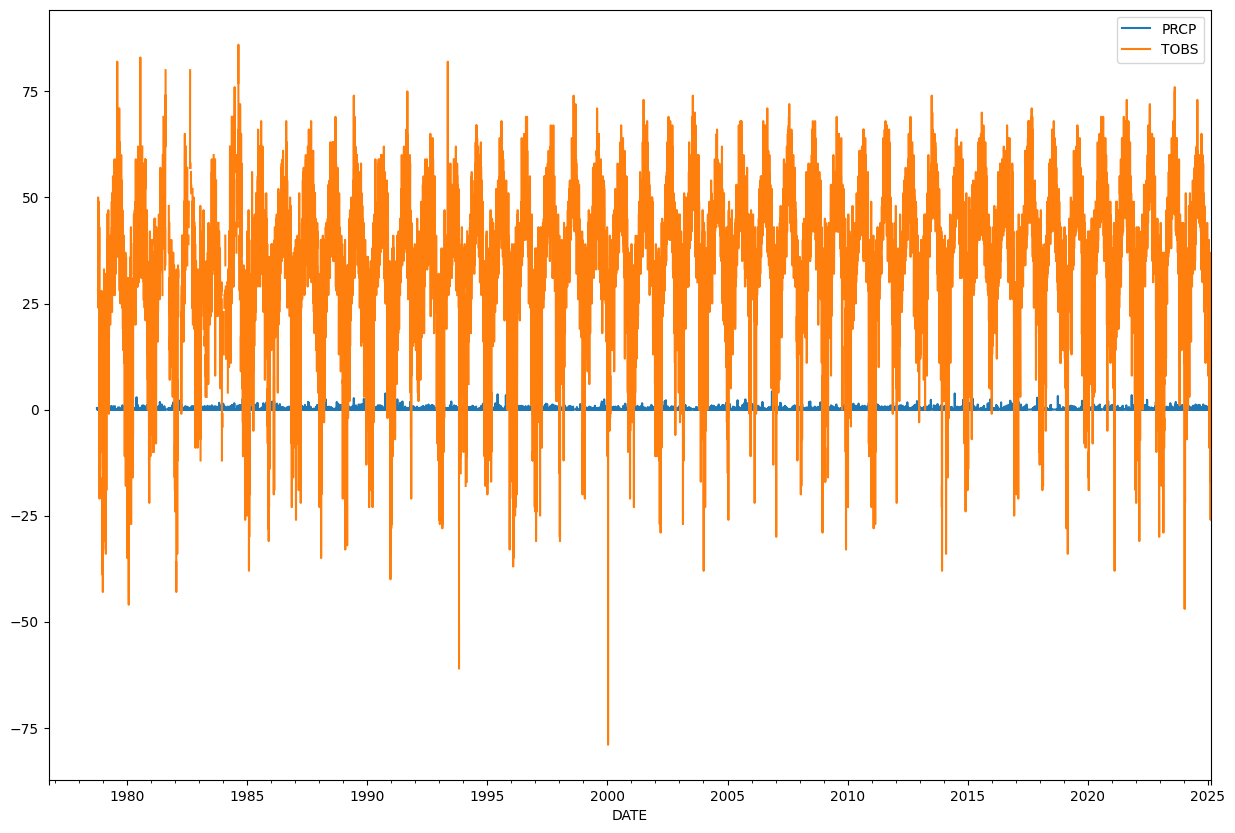

In [ ]:
# STEP 3: Plot the data
many_glacier_data.plot(figsize=(15,10))

In [ ]:
# STEP 4: Resample to look at annual mean
many_glacier_avg = many_glacier_data.resample('YE').mean()
many_glacier_avg

,PRCP,TOBS
DATE,,
1976-12-31,NaN,NaN
1977-12-31,NaN,NaN
1978-12-31,0.073913,16.958333
1979-12-31,0.100274,30.415473
1980-12-31,0.157377,30.069364
1981-12-31,0.110137,29.729008
1982-12-31,0.150137,26.740741
1983-12-31,0.108767,28.765258
1984-12-31,0.138525,30.477912


In [ ]:
# STEP 5: Subset the data to look at 1980-2020
many_glacier_1980_2020 = many_glacier_avg["1980":"2020"]
many_glacier_1980_2020

,PRCP,TOBS
DATE,,
1980-12-31,0.157377,30.069364
1981-12-31,0.110137,29.729008
1982-12-31,0.150137,26.740741
1983-12-31,0.108767,28.765258
1984-12-31,0.138525,30.477912
1985-12-31,0.132329,28.224658
1986-12-31,0.150411,33.024658
1987-12-31,0.106027,34.741047
1988-12-31,0.125137,33.284153


<Axes: title={'center': 'Avg Annual Temp - Many Glacier, MT'}, xlabel='DATE', ylabel='Temperature (F)'>

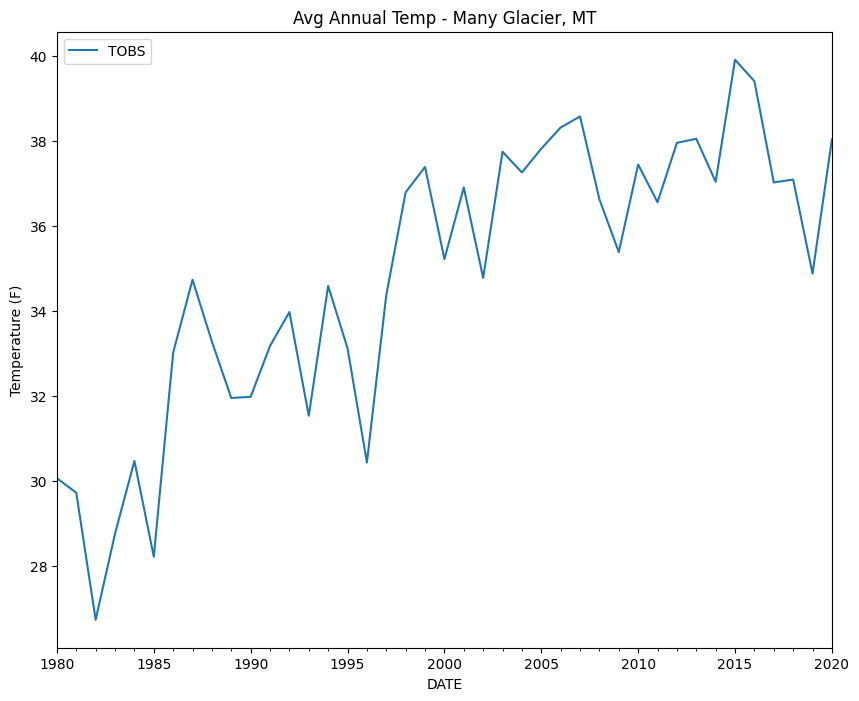

In [ ]:
# STEP 6: Plot 1980-2020 data
many_glacier_1980_2020.plot(y='TOBS', figsize=(10,8), ylabel='Temperature (F)',title='Avg Annual Temp - Many Glacier, MT')

In [ ]:
# STEP 7: Resetting the index
many_glacier_1980_2020 = many_glacier_1980_2020.reset_index()
many_glacier_1980_2020

,DATE,PRCP,TOBS
0,1980-12-31,0.157377,30.069364
1,1981-12-31,0.110137,29.729008
2,1982-12-31,0.150137,26.740741
3,1983-12-31,0.108767,28.765258
4,1984-12-31,0.138525,30.477912
5,1985-12-31,0.132329,28.224658
6,1986-12-31,0.150411,33.024658
7,1987-12-31,0.106027,34.741047
8,1988-12-31,0.125137,33.284153
9,1989-12-31,0.171507,31.958217


In [ ]:
# STEP 8: Remove year from DATE column and add as new variable
many_glacier_1980_2020['YEAR'] = many_glacier_1980_2020['DATE'].dt.year
many_glacier_1980_2020

,DATE,PRCP,TOBS,YEAR
0,1980-12-31,0.157377,30.069364,1980
1,1981-12-31,0.110137,29.729008,1981
2,1982-12-31,0.150137,26.740741,1982
3,1983-12-31,0.108767,28.765258,1983
4,1984-12-31,0.138525,30.477912,1984
5,1985-12-31,0.132329,28.224658,1985
6,1986-12-31,0.150411,33.024658,1986
7,1987-12-31,0.106027,34.741047,1987
8,1988-12-31,0.125137,33.284153,1988
9,1989-12-31,0.171507,31.958217,1989


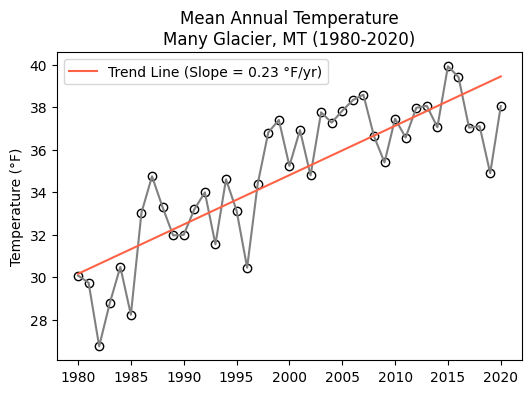

In [ ]:
# STEP 9: Plotting with a trendline (OPTIONAL IF TIME ALLOWS)
# Define our figure and axis objects
fig, ax = plt.subplots(figsize=(6,4))

# Compute linear regression
x = many_glacier_1980_2020['YEAR']
y = many_glacier_1980_2020['TOBS']

# Compute the slope (m) and intercept (b) of the line y = mx + b
m, b = np.polyfit(x, y, 1)

# Define degree symbol
degree_symbol = '\u00B0'

# Plot TOBS vs. YEAR as scatter plot
ax.scatter(x, y, color='white', edgecolor='black')

# Plot line graph
ax.plot(many_glacier_1980_2020['YEAR'],
        many_glacier_1980_2020['TOBS'],
        color='grey')

# Plot trend line
ax.plot(x, m*x + b, color='tomato', label=f'Trend Line (Slope = {m:.2f} {degree_symbol}F/yr)')

# Add legend
ax.legend()

# Add title and axis label
ax.set(title="Mean Annual Temperature\nMany Glacier, MT (1980-2020)",
       ylabel="Temperature (\u00B0F)")

plt.show()

***

# **NOW IT'S YOUR TURN!**
Try to recreate this workflow for another weather station of your choice. You can create new code cells below to get started (**HINT**: hover your mouse over the center of the screen below this cell and select the `+ Code` button). You can try copying and pasting the code you wrote for Many Glacier, MT and making changes. Be careful with copy/paste and double-check for errors before running your code.

Check the NOAA NCEI Climate Data Online **Search Tool** for a site/station that is interesting to you: https://www.ncei.noaa.gov/cdo-web/


Have fun!

In [ ]:
# STEP 1: Build endpoint request from NOAA/NCEI for Many Glacier, MT

many_glacier_url = (
    "https://www.ncei.noaa.gov/access/services/data/v1"
    "?dataset=daily-summaries"
    "&stations=USS0013A27S"
    "&startDate=1976-09-30"
    "&endDate=2025-02-21"
    "&dataTypes=TOBS,PRCP"
    "&includeStationName=true"
    "&includeStationLocation=1"
    "&units=standard")

many_glacier_url